# 01 – Data Exploration: NYC Airbnb 2019
**Group A · Track 1 (Classical ML: Regression & Clustering)**

**Goal of this notebook:** get to know the dataset before cleaning or modelling.

| Step | Content | Status |
|---|---|---|
| 1 | Load the dataset and describe it | ✅ this version |
| 2 | Visual exploration (price, room type, boroughs, hosts) | to do |
| 3 | Cleaning decisions → `decisions.md` | to do |

> Rule: no cleaning happens in this step. We only **look** at the data and write down what we notice.

## 1.0 Setup

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

SEED = 42  # used everywhere for reproducible results
np.random.seed(SEED)

# Show all columns and readable numbers
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.1.3


## 1.1 Load the dataset
The notebook looks for the file in the project's `data/raw/` folder.
In Google Colab, if the file is not found, it asks you to upload `AB_NYC_2019.csv`.

In [2]:
CANDIDATES = [
    Path("../data/raw/AB_NYC_2019.csv"),   # running from notebooks/
    Path("data/raw/AB_NYC_2019.csv"),      # running from project root
    Path("AB_NYC_2019.csv"),               # file uploaded next to the notebook (Colab)
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    try:
        from google.colab import files  # only exists in Colab
        files.upload()                  # choose AB_NYC_2019.csv
        DATA_PATH = Path("AB_NYC_2019.csv")
    except ImportError:
        raise FileNotFoundError("Put AB_NYC_2019.csv in data/raw/")

df = pd.read_csv(DATA_PATH, parse_dates=["last_review"])
print(f"Loaded {DATA_PATH} → {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded ../data/raw/AB_NYC_2019.csv → 48,895 rows × 16 columns


## 1.2 First look
Each **row is one listing** (one bookable place). Each **column is one feature** (one fact about it).

In [3]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.65,-73.97,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75,-73.98,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.81,-73.94,Private room,150,3,0,NaT,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.69,-73.96,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.80,-73.94,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 1.3 Data dictionary
What each column means, and how we plan to use it.

| Column | Meaning | Type | Planned role |
|---|---|---|---|
| `id` | Listing ID | ID | Not a feature (just a label) |
| `name` | Listing title written by the host | Text | Optional (keywords) |
| `host_id` | Host ID | ID | Group hosts; split data by host |
| `host_name` | Host's first name | Personal data | **Drop** (privacy, not useful) |
| `neighbourhood_group` | Borough (5 values) | Category | Feature |
| `neighbourhood` | Neighbourhood (221 values) | Category | Feature (needs encoding decision) |
| `latitude`, `longitude` | Map location | Number | Feature |
| `room_type` | Entire home / Private room / Shared room | Category | Feature |
| `price` | Nightly price in USD | Number | **Target** for regression |
| `minimum_nights` | Shortest stay allowed | Number | Feature |
| `number_of_reviews` | Total reviews ever | Number | Feature / demand proxy |
| `last_review` | Date of most recent review | Date | Turn into "days since last review" |
| `reviews_per_month` | Average reviews per month | Number | Main demand proxy |
| `calculated_host_listings_count` | Listings this host has | Number | Feature / host segmentation |
| `availability_365` | Days bookable in the next year | Number | Feature (careful: not demand) |

## 1.4 Column types and memory

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              48895 non-null  int64         
 1   name                            48879 non-null  object        
 2   host_id                         48895 non-null  int64         
 3   host_name                       48874 non-null  object        
 4   neighbourhood_group             48895 non-null  object        
 5   neighbourhood                   48895 non-null  object        
 6   latitude                        48895 non-null  float64       
 7   longitude                       48895 non-null  float64       
 8   room_type                       48895 non-null  object        
 9   price                           48895 non-null  int64         
 10  minimum_nights                  48895 non-null  int64         
 11  nu

## 1.5 Column overview
One row per column: its type, how many different values it has, how many are missing, and an example.

In [5]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "example": df.iloc[0],
})
overview

,dtype,n_unique,n_missing,pct_missing,example
id,int64,48895,0,0.00,2539
name,object,47905,16,0.03,Clean & quiet apt home by the park
host_id,int64,37457,0,0.00,2787
host_name,object,11452,21,0.04,John
neighbourhood_group,object,5,0,0.00,Brooklyn
neighbourhood,object,221,0,0.00,Kensington
latitude,float64,19048,0,0.00,40.65
longitude,float64,14718,0,0.00,-73.97
room_type,object,3,0,0.00,Private room
price,int64,674,0,0.00,149


## 1.6 Missing values – are they mistakes or meaningful?
Four columns have gaps. We check *why*, before deciding what to do.

In [6]:
no_reviews = df["number_of_reviews"] == 0
print("Listings with 0 reviews:                 ", f"{no_reviews.sum():,}")
print("Listings with empty reviews_per_month:   ", f"{df['reviews_per_month'].isna().sum():,}")
print("Empty reviews_per_month == 0 reviews?    ", (df["reviews_per_month"].isna() == no_reviews).all())
print("Empty last_review == 0 reviews?          ", (df["last_review"].isna() == no_reviews).all())
print("Missing name:", df["name"].isna().sum(), "| Missing host_name:", df["host_name"].isna().sum())

Listings with 0 reviews:                  10,052
Listings with empty reviews_per_month:    10,052
Empty reviews_per_month == 0 reviews?     True
Empty last_review == 0 reviews?           True
Missing name: 16 | Missing host_name: 21


## 1.7 Numeric columns – summary statistics
- **mean** = average, **50%** = median (middle value).
- If the mean is much bigger than the median, a few very large values are pulling it up (the data is **skewed**).

In [7]:
num_cols = ["price", "minimum_nights", "number_of_reviews", "reviews_per_month",
            "calculated_host_listings_count", "availability_365"]
stats = df[num_cols].describe(percentiles=[.25, .5, .75, .95, .99]).T
stats["skew"] = df[num_cols].skew()
stats

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew
price,"48,895.00",152.72,240.15,0.00,69.00,106.00,175.00,355.00,799.00,"10,000.00",19.12
minimum_nights,"48,895.00",7.03,20.51,1.00,1.00,3.00,5.00,30.00,45.00,"1,250.00",21.83
number_of_reviews,"48,895.00",23.27,44.55,0.00,1.00,5.00,24.00,114.00,214.00,629.00,3.69
reviews_per_month,"38,843.00",1.37,1.68,0.01,0.19,0.72,2.02,4.64,7.20,58.50,3.13
calculated_host_listings_count,"48,895.00",7.14,32.95,1.00,1.00,1.00,2.00,15.00,232.00,327.00,7.93
availability_365,"48,895.00",112.78,131.62,0.00,0.00,45.00,227.00,359.00,365.00,365.00,0.76


### Values that look suspicious

In [8]:
checks = {
    "price = 0": (df["price"] == 0).sum(),
    "price >= 1,000": (df["price"] >= 1000).sum(),
    "price = 10,000": (df["price"] == 10000).sum(),
    "minimum_nights > 365": (df["minimum_nights"] > 365).sum(),
    "minimum_nights >= 30 (monthly rentals)": (df["minimum_nights"] >= 30).sum(),
    "availability_365 = 0": (df["availability_365"] == 0).sum(),
}
pd.Series(checks, name="n_listings").to_frame()

,n_listings
price = 0,11
"price >= 1,000",298
"price = 10,000",3
minimum_nights > 365,14
minimum_nights >= 30 (monthly rentals),4507
availability_365 = 0,17533


## 1.8 Category columns – how many of each?

In [9]:
for col in ["room_type", "neighbourhood_group"]:
    counts = df[col].value_counts()
    display(pd.DataFrame({"count": counts, "pct": (counts / len(df) * 100).round(1)}))

,count,pct
room_type,,
Entire home/apt,25409,52.00
Private room,22326,45.70
Shared room,1160,2.40


,count,pct
neighbourhood_group,,
Manhattan,21661,44.30
Brooklyn,20104,41.10
Queens,5666,11.60
Bronx,1091,2.20
Staten Island,373,0.80


In [10]:
print("Number of neighbourhoods:", df["neighbourhood"].nunique())
print("\nTop 10 neighbourhoods by number of listings:")
df["neighbourhood"].value_counts().head(10)

Number of neighbourhoods: 221

Top 10 neighbourhoods by number of listings:


neighbourhood
Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1564
Midtown               1545
Name: count, dtype: int64

### First pricing picture: median price by borough and room type

In [11]:
df.pivot_table(index="neighbourhood_group", columns="room_type",
               values="price", aggfunc="median")

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100.00,53.50,40.00
Brooklyn,145.00,65.00,36.00
Manhattan,191.00,90.00,69.00
Queens,120.00,60.00,37.00
Staten Island,100.00,50.00,30.00


## 1.9 Duplicates and dates

In [12]:
print("Duplicate rows:       ", df.duplicated().sum())
print("Duplicate listing IDs:", df["id"].duplicated().sum())
print("last_review range:    ", df["last_review"].min().date(), "→", df["last_review"].max().date())

Duplicate rows:        0
Duplicate listing IDs: 0
last_review range:     2011-03-28 → 2019-07-08


## 1.10 Hosts – a first look
We plan to group **hosts**, so we check how listings are spread across them.

In [13]:
per_host = df.groupby("host_id").size()
bands = pd.cut(per_host, bins=[0, 1, 9, np.inf], labels=["1 listing", "2–9 listings", "10+ listings"])
host_summary = pd.DataFrame({
    "n_hosts": bands.value_counts().sort_index(),
    "n_listings": per_host.groupby(bands, observed=True).sum(),
})
host_summary["pct_listings"] = (host_summary["n_listings"] / len(df) * 100).round(1)
print(f"Unique hosts: {per_host.size:,}")
host_summary

Unique hosts: 37,457


,n_hosts,n_listings,pct_listings
1 listing,32303,32303,66.10
2–9 listings,5039,13415,27.40
10+ listings,115,3177,6.50


In [14]:
# The biggest hosts
top = per_host.sort_values(ascending=False).head(5).index
(df[df["host_id"].isin(top)]
   .groupby("host_id")  # no host_name: personal data
   .agg(listings=("id", "size"),
        pct_entire_home=("room_type", lambda s: round((s == "Entire home/apt").mean() * 100)),
        median_price=("price", "median"),
        median_availability=("availability_365", "median"))
   .sort_values("listings", ascending=False))

,listings,pct_entire_home,median_price,median_availability
host_id,,,,
219517861,327,98,228.00,328.00
107434423,232,100,302.50,285.00
30283594,121,100,239.00,352.00
137358866,103,2,41.00,235.00
16098958,96,99,180.00,312.00


## 1.11 Where are the listings, and how expensive are they? (map view)
Each dot is one listing, placed by its **longitude (x)** and **latitude (y)**, and **coloured by nightly price**.

- **Log colour scale, clipped to \$30–\$800** (about the 1st–99th percentile). Without it the colour bar runs \$0–\$10,000 and almost every dot is the same dark blue.
- Listings with a price of \$0 are left out (a log scale can't show 0).
- Dots are sorted by price, so expensive listings are drawn on top.

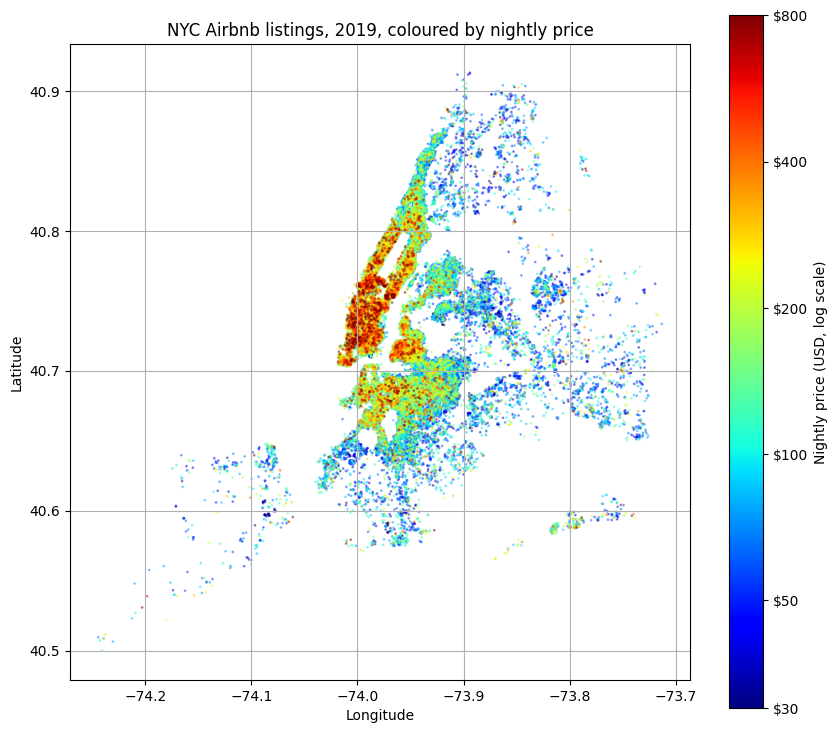

In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import FixedLocator, FuncFormatter

ax = df[df["price"] > 0].sort_values("price").plot(
    kind="scatter", x="longitude", y="latitude",
    c="price", cmap="jet", colorbar=True,
    norm=LogNorm(vmin=30, vmax=800, clip=True),   # log scale: $50, $100, $200, $400 are equal steps
    s=1, alpha=0.4, grid=True, figsize=(10, 9),
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("NYC Airbnb listings, 2019, coloured by nightly price")
ax.set_aspect(1 / np.cos(np.radians(40.7)))  # stops the map looking stretched at NYC's latitude

# Colour bar: label in dollars, full-strength colours
cbar = ax.figure.axes[-1]
cbar.set_ylabel("Nightly price (USD, log scale)")
cbar.yaxis.set_major_locator(FixedLocator([30, 50, 100, 200, 400, 800]))
cbar.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
cbar.yaxis.set_minor_locator(FixedLocator([]))
for coll in cbar.collections + cbar.images:
    coll.set_alpha(1)

ax.figure.savefig("../reports/figures/01_listings_map.png", dpi=150, bbox_inches="tight")
plt.show()

## 1.12 Correlations – which columns move together?
**Correlation** measures how strongly two columns move together, from **−1 to +1**:
- **+1**: when one goes up, the other always goes up.
- **0**: no relationship.
- **−1**: when one goes up, the other always goes down.

**Which type?** Pearson (the default) measures straight-line relationships and is easily distorted by extreme values such as the \$10,000 listings.
**Spearman** compares *rankings* (cheapest → most expensive) instead of raw values, so outliers barely affect it. Price is very skewed, so we use **Spearman**.

`room_type` is text, so we add one 0/1 column, `entire_home` (1 = entire home/apt), to include the biggest price driver.
Empty `reviews_per_month` values are skipped pair-by-pair (no cleaning in this notebook).

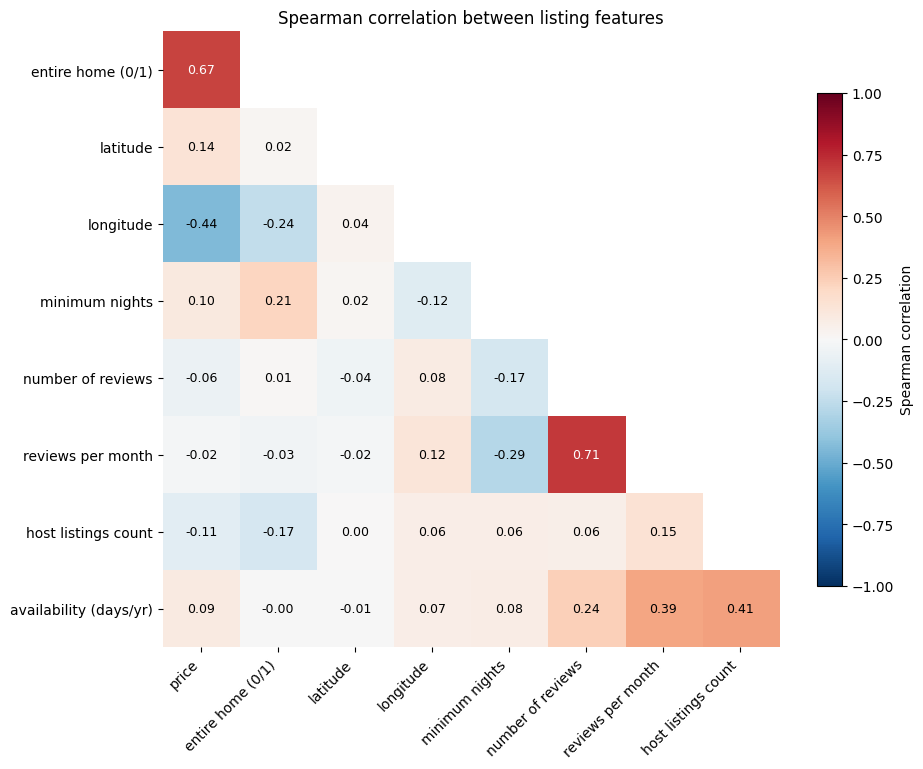

In [16]:
corr_df = df.assign(entire_home=(df["room_type"] == "Entire home/apt").astype(int))
labels = {
    "price": "price",
    "entire_home": "entire home (0/1)",
    "latitude": "latitude",
    "longitude": "longitude",
    "minimum_nights": "minimum nights",
    "number_of_reviews": "number of reviews",
    "reviews_per_month": "reviews per month",
    "calculated_host_listings_count": "host listings count",
    "availability_365": "availability (days/yr)",
}
corr = corr_df[list(labels)].corr(method="spearman").rename(index=labels, columns=labels)

# Show only the lower triangle (the upper half is a mirror copy),
# and drop the empty first row and last column
mask = np.triu(np.ones_like(corr, dtype=bool))
shown = corr.mask(mask).iloc[1:, :-1]

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(shown, cmap="RdBu_r", vmin=-1, vmax=1)  # red = positive, blue = negative, white = none
ax.set_xticks(range(shown.shape[1]), shown.columns, rotation=45, ha="right")
ax.set_yticks(range(shown.shape[0]), shown.index)
for r in range(shown.shape[0]):
    for col in range(r + 1):
        v = shown.iat[r, col]
        ax.text(col, r, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.5 else "black")
ax.spines[:].set_visible(False)
ax.set_title("Spearman correlation between listing features")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
fig.savefig("../reports/figures/01_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Correlation with price: Pearson vs Spearman
The gap between the two columns shows how much the extreme prices distort Pearson.

In [17]:
cols = list(labels)
price_corr = pd.DataFrame({
    "pearson": corr_df[cols].corr(method="pearson")["price"],
    "spearman": corr_df[cols].corr(method="spearman")["price"],
}).drop("price").rename(index=labels)
price_corr.sort_values("spearman", key=abs, ascending=False).round(2)

,pearson,spearman
entire home (0/1),0.26,0.67
longitude,-0.15,-0.44
latitude,0.03,0.14
host listings count,0.06,-0.11
minimum nights,0.04,0.10
availability (days/yr),0.08,0.09
number of reviews,-0.05,-0.06
reviews per month,-0.03,-0.02


## 1.13 Summary of Step 1 – what we learned

**Size:** 48,895 listings × 16 columns, posted by 37,457 hosts. No duplicate rows or IDs.

**Missing values:**
- `reviews_per_month` and `last_review` are empty for 10,052 listings — **exactly** the listings with 0 reviews. Not an error: these listings have no review rate. → fill with 0 in cleaning.
- `name` (16) and `host_name` (21) are missing a few values — not important (`host_name` will be dropped).

**Price (our target):**
- Median $106, mean $153 → strongly **skewed** (skew ≈ 19). → model log(price).
- 11 listings at $0 (not real prices) and a few up to $10,000. → need an outlier rule.

**Other suspicious values:**
- `minimum_nights` up to 1,250; 14 listings over a year. → cap or remove.
- 36% of listings have `availability_365 = 0` → probably inactive, **not** fully booked (to check in Step 2).

**Categories:** Entire home 52% / Private room 46% / Shared room 2%. Manhattan and Brooklyn have ~85% of listings. 221 neighbourhoods → needs an encoding decision.

**Hosts:** 86% of hosts have 1 listing, but 115 hosts have 10+ (largest: 327). → supports grouping hosts.

**Time:** one snapshot; last reviews run from 2011 to July 2019 → no seasonal price analysis possible.

**Correlations (Spearman):** `entire_home` (+0.67) and `longitude` (−0.44, i.e. cheaper further east) are the only strong links with price; reviews and availability are close to 0. Pearson understates these (0.26 and −0.15) because of the extreme prices. `number_of_reviews` and `reviews_per_month` are strongly linked (+0.71) → may not need both in the model.

**Next:** Step 2 – charts (price distribution, price by borough/room type, map, host types).